# 0.1 Data import

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

cwd = Path.cwd().resolve()
PROJECT_ROOT = next(
    (
        path for path in (cwd, *cwd.parents)
        if (path / "pyproject.toml").is_file() and (path / "data/raw").is_dir()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Cannot find project root with pyproject.toml and data/raw.")

RAW_DATA_DIR = PROJECT_ROOT / "data/raw"


In [2]:
files = {
    "variant_scores": "01_variant_scores.csv",
    "dose_response": "02_dose_response_scores.csv",
    "position_summary": "03_position_summary.csv",
    "position_lof_gof": "04_position_lof_gof.csv",
    "ligand_summary": "05_ligand_summary.csv",
}

datasets = {}

for name, filename in files.items():
    path = RAW_DATA_DIR / filename

    if not path.exists():
        print(f"MISSING: {filename}")
        continue

    datasets[name] = pd.read_csv(path)

    print(
        f"{name:20s} "
        f"{datasets[name].shape[0]:6d} rows × "
        f"{datasets[name].shape[1]:3d} columns"
    )

variant_scores        10178 rows × 106 columns
dose_response         10178 rows ×  49 columns
position_summary        399 rows ×  42 columns
position_lof_gof       5985 rows ×   8 columns
ligand_summary           15 rows ×  20 columns


<ipython-input-2-e42daa75d574>:18: DtypeWarning: Columns (89: Morphine_op_saturating, 90: Morphine_op_KA_unidentified, 96: Fentanyl_op_saturating) have mixed types. Specify dtype option on import or set low_memory=False.
  datasets[name] = pd.read_csv(path)


# 0.2 Data identifying

## 0.2.1 Ligands and column validation

In [3]:
df = datasets["variant_scores"]
ligand_df = datasets["ligand_summary"]

if ligand_df["ligand"].isna().any() or ligand_df["ligand"].duplicated().any():
    raise ValueError("Ligand names must be present and unique.")
ligands = ligand_df["ligand"].tolist()
if len(ligands) != 15:
    raise ValueError(f"Expected 15 ligands, found {len(ligands)}.")

ligand_effect_cols = [f"{ligand}_effect" for ligand in ligands]
ligand_se_cols = [f"{ligand}_effect_se" for ligand in ligands]
ligand_lfsr_cols = [f"{ligand}_lfsr" for ligand in ligands]
required_cols = ligand_effect_cols + ligand_se_cols + ligand_lfsr_cols
missing_cols = [col for col in required_cols if col not in df.columns]
if missing_cols:
    raise ValueError(f"Missing ligand columns: {missing_cols}")
non_numeric_cols = [
    col for col in required_cols if not pd.api.types.is_numeric_dtype(df[col])
]
if non_numeric_cols:
    raise TypeError(f"Non-numeric ligand columns: {non_numeric_cols}")

column_mapping = pd.DataFrame({
    "ligand": ligands,
    "effect_column": ligand_effect_cols,
    "se_column": ligand_se_cols,
    "lfsr_column": ligand_lfsr_cols,
})
print(f"Ligands: {len(ligands)}; matched effect/SE/LFSR columns: {len(required_cols)}")
display(column_mapping)


Ligands: 15; matched effect/SE/LFSR columns: 45


,ligand,effect_column,se_column,lfsr_column
0,Naloxone,Naloxone_effect,Naloxone_effect_se,Naloxone_lfsr
1,Naltrexone,Naltrexone_effect,Naltrexone_effect_se,Naltrexone_lfsr
2,Nalbuphine,Nalbuphine_effect,Nalbuphine_effect_se,Nalbuphine_lfsr
3,Buprenorphine,Buprenorphine_effect,Buprenorphine_effect_se,Buprenorphine_lfsr
4,Butorphanol,Butorphanol_effect,Butorphanol_effect_se,Butorphanol_lfsr
5,MP,MP_effect,MP_effect_se,MP_lfsr
6,TRV130,TRV130_effect,TRV130_effect_se,TRV130_lfsr
7,PZM21,PZM21_effect,PZM21_effect_se,PZM21_lfsr
8,Methadone,Methadone_effect,Methadone_effect_se,Methadone_lfsr
9,C6guano,C6guano_effect,C6guano_effect_se,C6guano_lfsr


## 0.2.2 Variant identifiers and receptor positions

In [4]:
missing_hgvs = int(df["hgvs"].isna().sum())
duplicated_hgvs = int(df["hgvs"].duplicated().sum())
print(f"HGVS: {df['hgvs'].nunique():,} unique; "
      f"{missing_hgvs} missing; {duplicated_hgvs} duplicates")
if missing_hgvs or duplicated_hgvs:
    raise ValueError("HGVS identifiers must be present and unique.")

print(f"Receptor positions: {df['position'].nunique()} unique; "
      f"range {df['position'].min():g}–{df['position'].max():g}; "
      f"{df['position'].isna().sum()} missing")


HGVS: 10,178 unique; 0 missing; 0 duplicates
Receptor positions: 399 unique; range 2–400; 0 missing


## 0.2.3 Variant types

In [5]:
variant_counts = (
    df["type"].value_counts(dropna=False)
    .rename_axis("variant_type").reset_index(name="count")
)
variant_counts["percentage"] = 100 * variant_counts["count"] / len(df)

display(variant_counts)


,variant_type,count,percentage
0,missense,7567,74.346630
1,insertion,1180,11.593633
2,deletion,1166,11.456082
3,synonymous,265,2.603655


## 0.2.4 Unfiltered DMS matrix

In [6]:
dms_matrix = df.set_index("hgvs")[ligand_effect_cols].copy()
dms_matrix.columns = ligands
complete_profiles = dms_matrix.notna().all(axis=1)

print(f"Unfiltered DMS matrix: {dms_matrix.shape[0]:,} × {dms_matrix.shape[1]}")
display(dms_matrix.head())


Unfiltered DMS matrix: 10,178 × 15


,Naloxone,Naltrexone,Nalbuphine,Buprenorphine,Butorphanol,MP,TRV130,PZM21,Methadone,C6guano,Fentanyl,Carfentanil,Morphine,DAMGO,SR17018
hgvs,,,,,,,,,,,,,,,
p.(D2A),-0.031823,0.042486,0.027261,0.006075,0.118965,0.201387,0.092042,0.153787,0.148148,0.027868,0.211125,0.062791,0.140871,0.023790,0.100106
p.(D2C),-0.108766,0.006947,-0.022378,-0.070764,-0.056330,-0.062438,0.044609,0.021013,0.009212,-0.037392,0.175153,-0.006217,0.020890,-0.039534,0.012592
p.(D2E),-0.010905,0.055698,-0.046181,0.031770,-0.054326,0.007032,0.020438,0.127248,0.068934,0.064967,0.083307,-0.039119,0.047611,-0.015659,0.069589
p.(D2F),-0.085038,0.077162,-0.092848,0.009881,-0.029667,0.009022,0.084642,0.095439,0.048333,0.023504,0.091915,-0.042957,0.104435,0.000117,0.012725
p.(D2G),0.006584,0.008376,-0.058232,-0.004067,-0.029043,0.037612,-0.016969,0.004277,0.048385,-0.060171,0.058960,-0.045887,0.069867,0.027678,-0.019495


## 0.2.5 Missingness and complete profiles

In [7]:
missing_summary = pd.DataFrame({
    "ligand": ligands,
    "missing_count": dms_matrix.isna().sum().to_numpy(),
    "missing_percent": 100 * dms_matrix.isna().mean().to_numpy(),
})

print(f"Complete profiles: {complete_profiles.sum():,} / {len(df):,}")
print(f"Complete missense profiles: "
      f"{(complete_profiles.to_numpy() & df['type'].eq('missense').to_numpy()).sum():,}")
print(f"Missing effect values: {dms_matrix.isna().sum().sum():,}")
display(missing_summary.sort_values("missing_count", ascending=False))


Complete profiles: 10,102 / 10,178
Complete missense profiles: 7,565
Missing effect values: 475


,ligand,missing_count,missing_percent
5,MP,48,0.471605
0,Naloxone,40,0.393005
3,Buprenorphine,36,0.353704
9,C6guano,35,0.343879
10,Fentanyl,35,0.343879
1,Naltrexone,34,0.334054
14,SR17018,34,0.334054
4,Butorphanol,33,0.324229
2,Nalbuphine,30,0.294753
7,PZM21,30,0.294753


# 0.3 Measurement quality and analysis cohorts

## 0.3.1 Reproduce the authors' PCA cohort

In [8]:
missense_mask = df["type"].eq("missense")
author_region_mask = df["position"].between(65, 355)
complete_mask = dms_matrix.notna().all(axis=1).to_numpy()
all_complete_missense_mask = missense_mask & complete_mask
author_cohort_mask = missense_mask & author_region_mask & complete_mask
synonymous_mask = df["type"].eq("synonymous")

cohort_summary = pd.DataFrame({
    "cohort": [
        "All variants", "All complete profiles", "All missense",
        "Complete missense (positions 2–400)", "Missense at positions 65–355",
        "Authors' PCA cohort: complete missense at positions 65–355",
    ],
    "n_variants": [
        len(df), complete_mask.sum(), missense_mask.sum(),
        all_complete_missense_mask.sum(), (missense_mask & author_region_mask).sum(),
        author_cohort_mask.sum(),
    ],
})
display(cohort_summary)

pca_cols = ["PCA_variant_PC1", "PCA_variant_PC2", "PCA_variant_PC3"]
saved_pca_mask = df[pca_cols].notna().all(axis=1)
print(f"Expected author cohort: 5,519; observed: {author_cohort_mask.sum():,}")
print("Identical HGVS membership to saved PCA scores:",
      author_cohort_mask.equals(saved_pca_mask))
print("Rows with partially missing PCA coordinates:",
      (df[pca_cols].notna().any(axis=1) & ~saved_pca_mask).sum())
print("Positions in author cohort:", df.loc[author_cohort_mask, "position"].nunique())

# Explicitly named matrices preserve both candidate analysis populations.
author_dms_matrix = dms_matrix.loc[df.loc[author_cohort_mask, "hgvs"]].copy()
complete_missense_dms_matrix = dms_matrix.loc[
    df.loc[all_complete_missense_mask, "hgvs"]
].copy()

Expected author cohort: 5,519; observed: 5,519
Identical HGVS membership to saved PCA scores: True
Rows with partially missing PCA coordinates: 0
Positions in author cohort: 291


,cohort,n_variants
0,All variants,10178
1,All complete profiles,10102
2,All missense,7567
3,Complete missense (positions 2–400),7565
4,Missense at positions 65–355,5520
5,Authors' PCA cohort: complete missense at posi...,5519


## 0.3.3 Missingness by variant class and ligand

In [9]:
completeness_by_type = (
    df.assign(complete_profile=complete_mask)
    .groupby("type", dropna=False)["complete_profile"]
    .agg(n_variants="size", n_complete="sum")
)
completeness_by_type["n_incomplete"] = (
    completeness_by_type["n_variants"] - completeness_by_type["n_complete"]
)
completeness_by_type["incomplete_percent"] = (
    100 * completeness_by_type["n_incomplete"] / completeness_by_type["n_variants"]
)
display(completeness_by_type)

missing_by_ligand_cohort = pd.DataFrame({
    "ligand": ligands,
    "all_variants_missing": dms_matrix.isna().sum().to_numpy(),
    "missense_missing": dms_matrix.loc[df.loc[missense_mask, "hgvs"]]
        .isna().sum().to_numpy(),
    "missense_65_355_missing": dms_matrix.loc[
        df.loc[missense_mask & author_region_mask, "hgvs"]
    ].isna().sum().to_numpy(),
})
display(missing_by_ligand_cohort)
print("Incomplete missense variants:")
display(df.loc[missense_mask & ~complete_mask, ["hgvs", "position"]])
print("Variants missing all 15 ligand effects:")
display(df.loc[dms_matrix.isna().all(axis=1).to_numpy(), ["hgvs", "type", "position"]])

Incomplete missense variants:
Variants missing all 15 ligand effects:


,n_variants,n_complete,n_incomplete,incomplete_percent
type,,,,
deletion,1166,1096,70,6.003431
insertion,1180,1179,1,0.084746
missense,7567,7565,2,0.026431
synonymous,265,262,3,1.132075


,ligand,all_variants_missing,missense_missing,missense_65_355_missing
0,Naloxone,40,2,1
1,Naltrexone,34,2,1
2,Nalbuphine,30,2,1
3,Buprenorphine,36,2,1
4,Butorphanol,33,2,1
5,MP,48,2,1
6,TRV130,24,2,1
7,PZM21,30,2,1
8,Methadone,29,2,1
9,C6guano,35,2,1


,hgvs,position
508,p.(C22A),22.0
5711,p.(P226E),226.0


,hgvs,type,position
326,p.(T14_D15insG),insertion,14.0
3175,p.(Q126_S127del),deletion,126.0
4600,p.(T182_R184del),deletion,182.0
5711,p.(P226E),missense,226.0
5931,p.(L234del),deletion,234.0


## 0.3.4 Effect, SE and LFSR consistency

In [10]:
consistency_rows = []
for ligand in ligands:
    effect = df[f"{ligand}_effect"]
    se = df[f"{ligand}_effect_se"]
    lfsr = df[f"{ligand}_lfsr"]
    consistency_rows.append({
        "ligand": ligand,
        "effect_missing": effect.isna().sum(),
        "se_missing": se.isna().sum(),
        "lfsr_missing": lfsr.isna().sum(),
        "missing_mask_mismatches": (
            (effect.isna() != se.isna()) | (effect.isna() != lfsr.isna())
        ).sum(),
        "infinite_values": np.isinf(pd.concat([effect, se, lfsr], axis=1)).sum().sum(),
        "se_nonpositive": se.le(0).sum(),
        "lfsr_outside_0_1": (lfsr.lt(0) | lfsr.gt(1)).sum(),
        "lfsr_above_0_5": lfsr.gt(0.5).sum(),
    })
consistency_summary = pd.DataFrame(consistency_rows).set_index("ligand")
with pd.option_context("display.max_columns", None):
    display(consistency_summary)

lfsr_long = df[["hgvs", "type", *ligand_lfsr_cols]].melt(
    id_vars=["hgvs", "type"], var_name="ligand", value_name="lfsr"
)
lfsr_long["ligand"] = lfsr_long["ligand"].str.removesuffix("_lfsr")
lfsr_review = lfsr_long.loc[lfsr_long["lfsr"].gt(0.5)].sort_values(
    "lfsr", ascending=False
)
print("LFSR > 0.5: variant–ligand records to investigate")
display(lfsr_review.reset_index(drop=True))

LFSR > 0.5: variant–ligand records to investigate


,effect_missing,se_missing,lfsr_missing,missing_mask_mismatches,infinite_values,se_nonpositive,lfsr_outside_0_1,lfsr_above_0_5
ligand,,,,,,,,
Naloxone,40,40,40,0,0,0,0,3
Naltrexone,34,34,34,0,0,0,0,1
Nalbuphine,30,30,30,0,0,0,0,2
Buprenorphine,36,36,36,0,0,0,0,1
Butorphanol,33,33,33,0,0,0,0,1
MP,48,48,48,0,0,0,0,2
TRV130,24,24,24,0,0,0,0,2
PZM21,30,30,30,0,0,0,0,3
Methadone,29,29,29,0,0,0,0,3


,hgvs,type,ligand,lfsr
0,p.(T281T),synonymous,SR17018,0.50225
1,p.(T155T),synonymous,DAMGO,0.50200
2,p.(T396T),synonymous,Butorphanol,0.50175
3,p.(A325A),synonymous,Methadone,0.50175
4,p.(C332C),synonymous,TRV130,0.50175
5,p.(T14T),synonymous,Naloxone,0.50175
6,p.(V293V),synonymous,TRV130,0.50150
7,p.(P7P),synonymous,SR17018,0.50150
8,p.(L76L),synonymous,PZM21,0.50150
9,p.(S30S),synonymous,Morphine,0.50150


## 0.3.5 Descriptive distributions and synonymous reference

In [11]:
uncertainty_rows = []
reference_rows = []
for ligand in ligands:
    effect = df.loc[author_cohort_mask, f"{ligand}_effect"]
    se = df.loc[author_cohort_mask, f"{ligand}_effect_se"]
    lfsr = df.loc[author_cohort_mask, f"{ligand}_lfsr"]
    syn = df.loc[synonymous_mask, f"{ligand}_effect"]
    uncertainty_rows.append({
        "ligand": ligand, "n_effect": effect.count(), "n_se": se.count(),
        "n_lfsr": lfsr.count(), "effect_q05": effect.quantile(0.05),
        "effect_median": effect.median(), "effect_q95": effect.quantile(0.95),
        "se_median": se.median(), "se_q95": se.quantile(0.95),
        "lfsr_median": lfsr.median(), "lfsr_q95": lfsr.quantile(0.95),
    })
    reference_rows.append({
        "ligand": ligand, "n_synonymous": syn.count(),
        "synonymous_mean": syn.mean(), "synonymous_median": syn.median(),
        "synonymous_sd": syn.std(), "synonymous_q05": syn.quantile(0.05),
        "synonymous_q95": syn.quantile(0.95),
    })
uncertainty_summary = pd.DataFrame(uncertainty_rows).set_index("ligand")
synonymous_reference = pd.DataFrame(reference_rows).set_index("ligand")
with pd.option_context("display.max_columns", None):
    display(uncertainty_summary.round(5))
    display(synonymous_reference.round(5))

,n_effect,n_se,n_lfsr,effect_q05,effect_median,effect_q95,se_median,se_q95,lfsr_median,lfsr_q95
ligand,,,,,,,,,,
Naloxone,5519,5519,5519,-0.16545,-0.00571,0.17234,0.15713,0.17537,0.33950,0.48525
Naltrexone,5519,5519,5519,-0.17995,-0.01667,0.16397,0.14833,0.16568,0.30775,0.48275
Nalbuphine,5519,5519,5519,-0.25798,-0.05170,0.12241,0.15954,0.17741,0.29650,0.47802
Buprenorphine,5519,5519,5519,-0.24667,-0.03984,0.13348,0.17745,0.19568,0.31800,0.48077
Butorphanol,5519,5519,5519,-0.29634,-0.04681,0.13918,0.14168,0.15968,0.25675,0.47880
MP,5519,5519,5519,-0.25748,-0.04572,0.14581,0.19872,0.21952,0.32650,0.48225
TRV130,5519,5519,5519,-0.34411,-0.06037,0.13154,0.15408,0.17497,0.26725,0.47730
PZM21,5519,5519,5519,-0.39163,-0.08292,0.11431,0.16044,0.18034,0.25000,0.47650
Methadone,5519,5519,5519,-0.41109,-0.10962,0.11163,0.16296,0.18378,0.20975,0.46902


,n_synonymous,synonymous_mean,synonymous_median,synonymous_sd,synonymous_q05,synonymous_q95
ligand,,,,,,
Naloxone,262,0.00005,0.00446,0.08829,-0.13110,0.14267
Naltrexone,264,0.00010,0.00074,0.08494,-0.12072,0.12868
Nalbuphine,263,0.00013,-0.00312,0.09162,-0.13336,0.13358
Buprenorphine,262,-0.00013,-0.01151,0.11123,-0.13833,0.17370
Butorphanol,263,-0.00003,0.00462,0.08009,-0.11271,0.11606
MP,262,0.00032,0.00359,0.10524,-0.16538,0.16679
TRV130,262,-0.00007,-0.00574,0.08607,-0.13559,0.13978
PZM21,263,-0.00016,-0.01706,0.09240,-0.13459,0.17062
Methadone,263,-0.00006,-0.00908,0.10232,-0.14963,0.17479


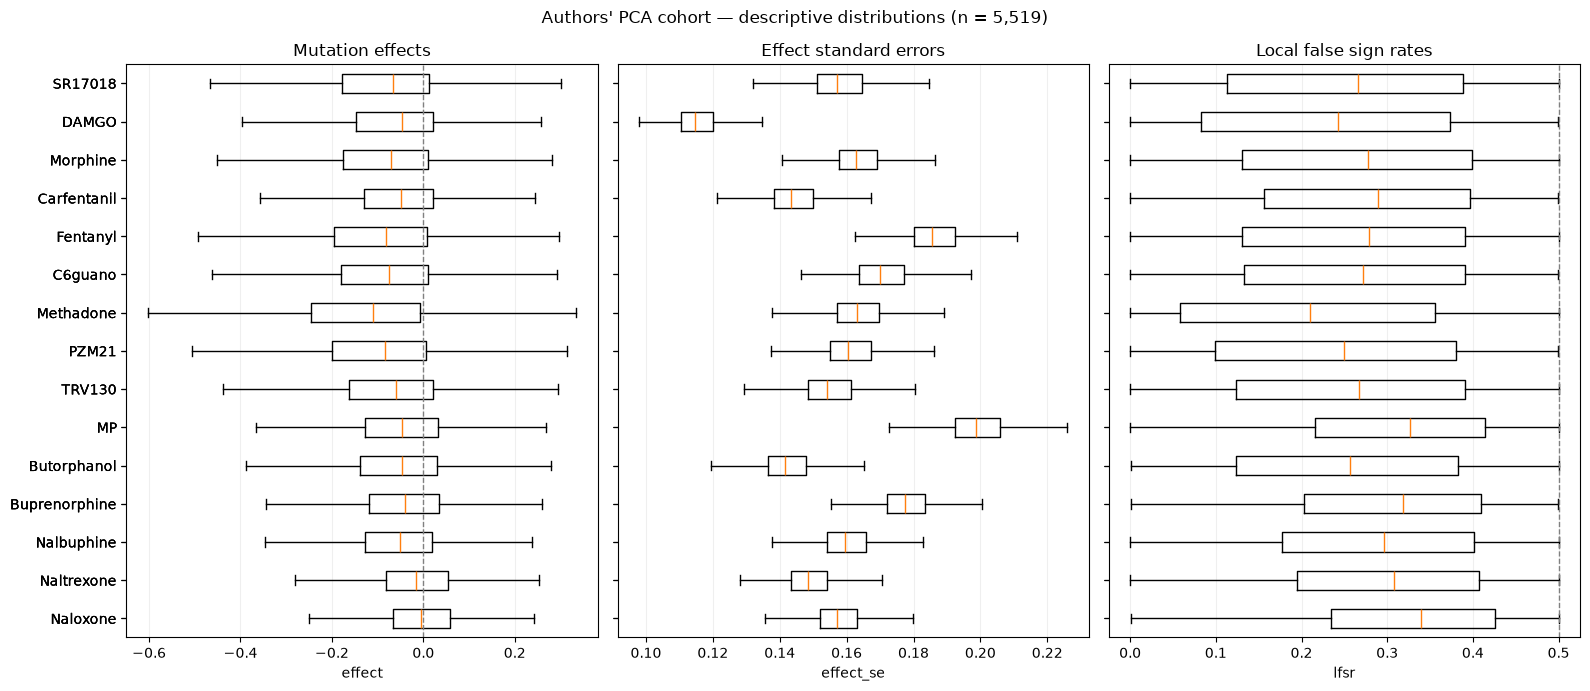

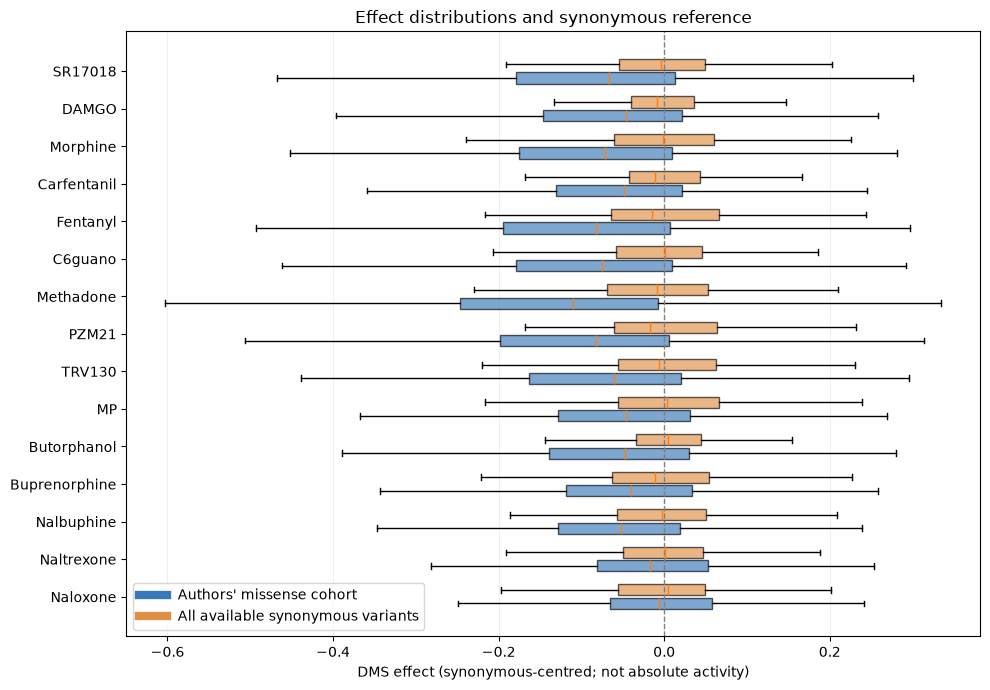

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 7), sharey=True)
for ax, suffix, title in zip(
    axes,
    ["effect", "effect_se", "lfsr"],
    ["Mutation effects", "Effect standard errors", "Local false sign rates"],
):
    values = [df.loc[author_cohort_mask, f"{ligand}_{suffix}"].dropna()
              for ligand in ligands]
    ax.boxplot(values, orientation="horizontal", tick_labels=ligands,
               showfliers=False)
    ax.set_title(title)
    ax.set_xlabel(suffix)
    ax.grid(axis="x", alpha=0.2)
axes[0].axvline(0, color="grey", linestyle="--", linewidth=1)
axes[2].axvline(0.5, color="grey", linestyle="--", linewidth=1)
fig.suptitle("Authors' PCA cohort — descriptive distributions (n = "
             f"{author_cohort_mask.sum():,})")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 7))
positions = np.arange(1, len(ligands) + 1)
for mask, offset, color, label in [
    (author_cohort_mask, -0.18, "#3779b9", "Authors' missense cohort"),
    (synonymous_mask, 0.18, "#df8f44", "All available synonymous variants"),
]:
    values = [df.loc[mask, f"{ligand}_effect"].dropna() for ligand in ligands]
    boxes = ax.boxplot(values, positions=positions + offset, widths=0.30,
                       orientation="horizontal", patch_artist=True,
                       showfliers=False, manage_ticks=False)
    for box in boxes["boxes"]:
        box.set_facecolor(color)
        box.set_alpha(0.65)
    ax.plot([], [], color=color, linewidth=6, label=label)
ax.set_yticks(positions, ligands)
ax.axvline(0, color="grey", linestyle="--", linewidth=1)
ax.set_xlabel("DMS effect (synonymous-centred; not absolute activity)")
ax.set_title("Effect distributions and synonymous reference")
ax.grid(axis="x", alpha=0.2)
ax.legend(loc="best")
fig.tight_layout()
plt.show()